# Experiment 6: Simulations from real genomes

**Why:** Experiments 1–4 used a random 1 Mb sequence, and Experiment 5 had no true answer (dnadiff itself overestimates under
uneven rates). Here genome B is made from a **real chromosome** with a **known** true ANI, so every tool can be scored against the truth
on realistic sequence. This is the proposal's "three real bacterial genomes, 10 replicates, gene-content differences and small indels".

**Design**
- Genome A: the chromosome of *E. coli*, *K. pneumoniae* and *S. pneumoniae* (GC 51%, 57%, 40%), from `data/genomes`.
- Genome B: A mutated in 5 kb regions with a rate pattern: **uniform, gamma α = 2, gamma α = 0.5, two-class, wave,
  gamma α = 2 + 20% foreign genes** (regions replaced by real *Bacillus cereus* sequence).
  Small insertions/deletions (1–20 bp) occur at 10% of the local substitution rate.
- True ANI = identity over shared, non-deleted sites. Targets 80–97%, **10 replicates**: 3 × 6 × 7 × 10 = **1,260 pairs**.
- Scored: **Mash, sourmash, skani, dnadiff** (dnadiff on replicates 0–2 only: it is the slowest step and a reference, not an estimator)
  and our estimators copied unchanged from the other notebooks (uniform control, original, C, G).

**Nothing in the other notebooks or their results is touched.** Everything is written to `results/realsim/`.
The raw k-mer counts of every pair (k = 11–31, and per-1 kb-window hits at k = 15 and 21) are also saved in
`results/realsim/curves/`, so new estimators (e.g. the two-rate-class model) can be scored later **without re-running**.

**How to run:** set `MY_WORKERS` in the next cell, then Runtime → Run all.
- Alone: `MY_WORKERS = [0, 1]` (2 parallel workers, uses both Colab CPUs) → about **3–4 hours**.
- Split with your teammate: one person `[0, 1]`, the other `[2, 3]`, both with `N_WORKERS = 4` → about **1.5–2 hours each**.
- It is **resumable**: if Colab disconnects, just Run all again; finished pairs are skipped. Replicates finish in order,
  so a partial run is still a complete, smaller experiment.
- Set `QUICK = True` for a 10-minute test run (36 pairs, written to separate `_quick` files).

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
PROJECT   = "/content/drive/MyDrive/CMPS355_ANI_Project"
TOOLS     = "/content/tools"
N_WORKERS = 2          # total workers across everyone running this (2 = alone, 4 = split between two people)
MY_WORKERS = [0, 1]    # alone: [0, 1]; if split: person 1 -> [0, 1], person 2 -> [2, 3]
QUICK     = False      # True = short test run (36 pairs) into separate _quick files

import os
OUT = f"{PROJECT}/results/realsim"; os.makedirs(OUT, exist_ok=True); os.makedirs(TOOLS, exist_ok=True)
assert os.path.exists(f"{PROJECT}/data/genomes/GCF_000597845.1.fna"), "genomes not found: is CMPS355_ANI_Project in My Drive?"
print("Writing to:", OUT)

Writing to: /content/drive/MyDrive/CMPS355_ANI_Project/results/realsim


In [ ]:
# ---------------- tools: pyskani, sourmash, Mash 2.3, MUMmer (same versions/sources as the other notebooks) ----------------
import subprocess, shutil
subprocess.run("pip -q install pyskani sourmash", shell=True, check=True)
if not os.path.exists(f"{TOOLS}/mash-Linux64-v2.3/mash"):
    subprocess.run(f"cd {TOOLS} && wget -q https://github.com/marbl/Mash/releases/download/v2.3/mash-Linux64-v2.3.tar "
                   "&& tar -xf mash-Linux64-v2.3.tar", shell=True, check=True)
if shutil.which("dnadiff") is None:
    subprocess.run("apt-get -qq update > /dev/null && apt-get -qq install -y mummer > /dev/null", shell=True, check=True)
import pyskani, sourmash
print("pyskani", pyskani.__version__, "| sourmash", sourmash.VERSION, "| dnadiff", shutil.which("dnadiff"), "| CPUs", os.cpu_count())

pyskani 0.2.0 | sourmash 4.9.4 | dnadiff /usr/bin/dnadiff | CPUs 2


### The simulation script
Written to `/content/realsim.py` and run as background workers (one per CPU). A copy is also saved next to the results.

In [ ]:
%%writefile /content/realsim.py
"""Real-genome simulations: genome pairs built from REAL chromosomes with a known true ANI.

Genome A = a real chromosome. Genome B = A mutated with a known regional rate pattern (5 kb regions),
plus small insertions/deletions at the same local rate, plus (in one setting) whole regions replaced by
real sequence from another genus ("genes only B has"). True ANI = identity over shared, non-deleted sites.

Every pair is scored by: Mash, sourmash, skani, dnadiff (published tools) and by the project's
estimators, copied unchanged from the notebooks: uniform control, original multi-k gamma,
C (window s) and G (window s + aligned-only).

Usage:  python realsim.py PROJECT_DIR TOOLS_DIR WORKER N_WORKERS [--quick]
  - resumable: finished jobs are skipped; each worker appends to its own CSV in PROJECT_DIR/results/realsim/
  - job j always uses random seed 10000 + j, so results do not depend on how the work is split
"""
import os, sys, json, time, subprocess
import numpy as np, pandas as pd
from scipy.optimize import curve_fit
from scipy.special import gammainc
import pyskani, sourmash

PROJECT, TOOLS, WID, NW = sys.argv[1], sys.argv[2], int(sys.argv[3]), int(sys.argv[4])
QUICK = "--quick" in sys.argv
OUT = f"{PROJECT}/results/realsim"; os.makedirs(OUT, exist_ok=True)
import shutil
MASH_BIN = f"{TOOLS}/mash-Linux64-v2.3/mash"
if not os.path.exists(MASH_BIN): MASH_BIN = shutil.which("mash")      # e.g. on a cluster, Mash installed with conda
assert MASH_BIN and shutil.which("dnadiff"), "Mash or dnadiff not found"

# ---------------- design ----------------
GENOMES = {"E. coli": "GCF_000597845.1",            # 4.76 Mb, GC 51%
           "K. pneumoniae": "GCF_000364385.3",      # 5.44 Mb chromosome, GC 57%
           "S. pneumoniae": "GCF_001095405.2"}      # 2.15 Mb, GC 40%
FOREIGN = "GCF_000635895.2"                         # Bacillus cereus: source of foreign genes
REGION_LEN, WIN = 5_000, 1000
KS = np.arange(15, 32, 2); K_MASH = 21; QSTAR = 0.78
KS_SAVE = np.arange(11, 32, 2)                      # raw counts saved for k = 11..31 (estimators use 15..31)
WIN_KS = (15, 21)                                   # per-1kb-window hit counts saved at these k (for later estimators)
TARGETS = [0.80, 0.84, 0.88, 0.91, 0.93, 0.95, 0.97]
REPS = 10
DNADIFF_REPS = 3                                    # dnadiff (slowest step, ~70% of the time) only on replicates 0-2:
                                                    # it is a reference tool, not an estimator; 378 pairs are plenty
INDEL_RATIO = 0.1                                   # indel events per substitution, at the same local rate

# ---------------- reading / writing ----------------
LOOKUP = np.full(256, 255, dtype=np.uint8)
for i, b in enumerate(b"ACGT"): LOOKUP[b] = i
for i, b in enumerate(b"acgt"): LOOKUP[b] = i
DEC = np.frombuffer(b"ACGT", dtype=np.uint8)

def chromosome(acc):
    contigs, cur = [], []
    for line in open(f"{PROJECT}/data/genomes/{acc}.fna", "rb"):
        if line.startswith(b">"):
            if cur: contigs.append(b"".join(cur)); cur = []
        else: cur.append(line.strip())
    contigs.append(b"".join(cur))
    s = LOOKUP[np.frombuffer(max(contigs, key=len), dtype=np.uint8)]
    return s[s < 4]

def write_fa(path, seq):
    with open(path, "wb") as f: f.write(b">seq\n" + DEC[seq].tobytes() + b"\n")

# ---------------- rate patterns (as in the notebooks, plus the generator passed in) ----------------
def rates_uniform(rng, n): return np.ones(n)
def rates_gamma(alpha): return lambda rng, n: rng.gamma(alpha, 1 / alpha, n)
def rates_two_class(rng, n, frac_fast=0.3, fold=5):
    r = np.where(rng.random(n) < frac_fast, fold, 1.0); return r / r.mean()
def rates_wave(rng, n, fold=4, waves=2):
    x = np.arange(n) / n; amp = (fold - 1) / (fold + 1)
    r = 1 + amp * np.sin(2 * np.pi * waves * x + rng.uniform(0, 2 * np.pi)); return r / r.mean()

SETTINGS = {"Uniform": (rates_uniform, 0.0),
            "Gamma a=2": (rates_gamma(2.0), 0.0),
            "Gamma a=0.5": (rates_gamma(0.5), 0.0),
            "Two-class": (rates_two_class, 0.0),
            "Wave": (rates_wave, 0.0),
            "Gamma a=2 + 20% foreign genes": (rates_gamma(2.0), 0.20)}

def make_pair(rng, A, mean_p, rate_fn, gene_diff, foreign):
    L = len(A); n_reg = -(-L // REGION_LEN)
    reg = np.arange(L) // REGION_LEN
    p_site = np.clip(mean_p * rate_fn(rng, n_reg)[reg], 0, 0.75)
    sub = rng.random(L) < p_site
    B = A.copy(); B[sub] = (A[sub] + rng.integers(1, 4, sub.sum(), dtype=np.uint8)) % 4
    rep = rng.choice(n_reg - 1, int(round(gene_diff * n_reg)), replace=False)       # never the short last region
    is_rep = np.isin(reg, rep)
    for r in rep:
        o = rng.integers(0, len(foreign) - REGION_LEN)
        B[r * REGION_LEN:(r + 1) * REGION_LEN] = foreign[o:o + REGION_LEN]
    ev = np.flatnonzero((rng.random(L) < p_site * INDEL_RATIO) & ~is_rep)
    lens = np.minimum(rng.geometric(1 / 3, ev.size), 20)
    is_ins = rng.random(ev.size) < 0.5
    deleted = np.zeros(L, bool)
    for p, l in zip(ev[~is_ins], lens[~is_ins]): deleted[p:p + l] = True
    pieces, last = [], 0
    for p, l in zip(ev[is_ins], lens[is_ins]):
        pieces.append(B[np.flatnonzero(~deleted[last:p]) + last]); pieces.append(rng.integers(0, 4, l, dtype=np.uint8)); last = p
    pieces.append(B[np.flatnonzero(~deleted[last:]) + last])
    keep = ~is_rep & ~deleted
    rid = 1 - np.bincount(reg, weights=sub & keep, minlength=n_reg) / np.maximum(np.bincount(reg, weights=keep, minlength=n_reg), 1)
    shared_regions = ~np.isin(np.arange(n_reg), rep)
    return np.concatenate(pieces), 1 - sub[keep].mean(), 1 - is_rep.mean(), rid[shared_regions]

# ---------------- k-mers ----------------
def pack(seq, k):
    n = len(seq) - k + 1; v = np.zeros(n, dtype=np.uint64)
    for j in range(k): v = (v << np.uint64(2)) | seq[j:j + n].astype(np.uint64)
    return v
def uniq(v):
    v = np.sort(v); return v[np.concatenate(([True], v[1:] != v[:-1]))]
def member(x, sorted_set):
    i = np.searchsorted(sorted_set, x); i[i == sorted_set.size] = 0
    return sorted_set[i] == x

# ---------------- estimators (copied unchanged from the notebooks) ----------------
def est_mash(C):
    C21 = C[KS == K_MASH][0]; J = C21 / (2 - C21); return 1 + np.log(2 * J / (1 + J)) / K_MASH
def est_uniform(C):
    slope, intercept = np.polyfit(KS, np.log(C), 1); return np.exp(slope), np.exp(intercept), -slope
def gamma_model(k, s, d, alpha): return np.log(s) - alpha * np.log1p(k * d / alpha)
def est_gamma(C):
    y = np.log(C); _, s0, d0 = est_uniform(C); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            p, _ = curve_fit(gamma_model, KS, y, p0=[min(s0, 0.99), max(d0, 1e-4), a0],
                             bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(KS, *p) - y) ** 2)
            if best is None or err < best[1]: best = (p, err)
        except RuntimeError: pass
    s, d, alpha = best[0]; return (1 + d / alpha) ** (-alpha), s, alpha
def fit_gamma_s_fixed(C, s_fixed):
    y = np.log(np.maximum(C, 1e-12)); slope, _ = np.polyfit(KS, y, 1); d0 = max(-slope, 1e-4); best = None
    f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
    for a0 in [0.3, 1, 5, 50]:
        try:
            q, _ = curve_fit(f, KS, y, p0=[d0, a0], bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000)
            sse = np.sum((f(KS, *q) - y) ** 2)
            if best is None or sse < best[1]: best = (q, sse)
        except (RuntimeError, ValueError): pass
    return best[0]
def ani_gamma(d, a): return (1 + d / a) ** (-a)
def ani_gamma_aligned(d, a, qstar=QSTAR):
    lam, scale = -np.log(qstar), d / a
    p_al = gammainc(a, lam / scale)
    return (1 + scale) ** (-a) * gammainc(a, lam * (1 + scale) / scale) / max(p_al, 1e-300)

# ---------------- published tools ----------------
def parse_dnadiff(path):
    ani = al = None; one = False
    for line in open(path):
        if line.startswith("AlignedBases") and al is None: al = float(line.split()[1].split("(")[1].rstrip("%)")) / 100
        if line.startswith("1-to-1"): one = True
        if one and line.startswith("AvgIdentity"): ani = float(line.split()[1]) / 100; break
    return ani, al

def frac_minhash(seq_bytes):
    mh = sourmash.MinHash(n=0, ksize=21, scaled=1000); mh.add_sequence(seq_bytes.decode(), force=True); return mh

# ---------------- main loop ----------------
def main():
    tmp = f"{os.environ.get('TMPDIR', '/tmp')}/realsim_w{WID}"; os.makedirs(tmp, exist_ok=True)   # node-local temp files
    tag = "_quick" if QUICK else ""
    CURVES = f"{OUT}/curves{tag}"; os.makedirs(CURVES, exist_ok=True)   # raw k-mer counts per pair (job_<j>.npz)
    out_csv = f"{OUT}/raw_w{WID}{tag}.csv"
    done = set()                                     # finished jobs from ANY worker file, so the split can change safely
    for f in os.listdir(OUT):
        if f.startswith("raw_w") and f.endswith(f"{tag}.csv") and (QUICK or "_quick" not in f):
            done |= set(pd.read_csv(f"{OUT}/{f}").job)
    foreign = chromosome(FOREIGN)
    # replicate is the OUTER loop: if a run stops early, the finished replicates are complete
    jobs = [(g, s, t, r) for r in range(REPS) for g in GENOMES for s in SETTINGS for t in TARGETS]
    sel = [j for j in range(len(jobs)) if not QUICK or (jobs[j][2] in (0.88, 0.95) and jobs[j][3] == 0)]
    mine = [j for j in sel[WID::NW] if j not in done]
    print(f"worker {WID}/{NW}: {len(mine)} jobs to do ({len(done)} finished overall)", flush=True)
    cur = None
    for n, j in enumerate(mine, 1):
        gname, sname, target, rep = jobs[j]; t0 = time.time()
        if cur is None or cur[0] != gname:
            A = chromosome(GENOMES[gname]); faA = f"{tmp}/A.fa"; write_fa(faA, A)
            subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", f"{tmp}/A", faA], capture_output=True, check=True)
            skdb = pyskani.Database(); skdb.sketch("A", DEC[A].tobytes())
            cur = (gname, A, faA, {k: uniq(pack(A, k)) for k in KS_SAVE}, {k: pack(A, k) for k in WIN_KS}, skdb,
                   frac_minhash(DEC[A].tobytes()))
        _, A, faA, kA, Apos, skdb, smA = cur
        A21 = Apos[21]
        rng = np.random.default_rng(10_000 + j)
        fn, gd = SETTINGS[sname]
        B, true_ani, true_s, rid = make_pair(rng, A, 1 - target, fn, gd, foreign)
        Bbytes = DEC[B].tobytes()
        # shared-k-mer curve (same chance correction as the main notebook)
        C, raw, kBs = [], {"nA": [], "nB": [], "shared": []}, {}
        for k in KS_SAVE:
            kB = uniq(pack(B, k)); sh = int(member(kB, kA[k]).sum())
            raw["nA"].append(kA[k].size); raw["nB"].append(kB.size); raw["shared"].append(sh)
            if k in WIN_KS: kBs[k] = kB
            if k in KS: C.append(max(sh - kA[k].size * kB.size / 4.0 ** k, 1) / kA[k].size)
        C = np.array(C)
        win = {k: np.bincount(np.arange(Apos[k].size) // WIN, weights=member(Apos[k], kBs[k])).astype(np.uint16) for k in WIN_KS}
        sw = (win[21] >= 1).mean()
        np.savez_compressed(f"{CURVES}/job_{j}.npz", ks=KS_SAVE, nA=np.array(raw["nA"]), nB=np.array(raw["nB"]),
                            shared=np.array(raw["shared"]), win15=win[15], win21=win[21],
                            region_identity=rid.astype(np.float32), win_len=WIN, region_len=REGION_LEN)
        g_ani, g_s, g_a = est_gamma(C)
        dC, aC = fit_gamma_s_fixed(C, min(sw, 1))
        # published tools
        faB = f"{tmp}/B.fa"; write_fa(faB, B)
        mash = 1 - float(subprocess.run([MASH_BIN, "dist", f"{tmp}/A.msh", faB], capture_output=True, text=True,
                                        check=True).stdout.split("\t")[2])
        h = skdb.query("B", Bbytes); skani = h[0].identity if h else np.nan
        r = smA.containment_ani(frac_minhash(Bbytes)); smash = r.ani if r.ani is not None else np.nan
        dd = dd_al = np.nan
        if rep < DNADIFF_REPS:
            subprocess.run(["dnadiff", "-p", f"{tmp}/dd", faA, faB], capture_output=True, check=True, cwd=tmp)
            dd, dd_al = parse_dnadiff(f"{tmp}/dd.report")
        row = {"job": j, "genome": gname, "setting": sname, "target": target, "rep": rep, "true": true_ani, "true_s": true_s,
               "Mash (tool)": mash, "sourmash": smash, "skani": skani, "dnadiff": dd, "dnadiff_aligned": dd_al,
               "Mash formula": est_mash(C), "uniform (control)": est_uniform(C)[0], "original": g_ani,
               "C: window s": ani_gamma(dC, aC), "G: window s + aligned-only": ani_gamma_aligned(dC, aC),
               "s_orig": g_s, "alpha_orig": g_a, "s_window": sw, "alpha_C": aC,
               "region_sd": float(rid.std()), "region_min": float(rid.min()), "seconds": round(time.time() - t0, 1)}
        pd.DataFrame([row]).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
        print(f"[w{WID} {n}/{len(mine)}] {gname} | {sname} | {target}: true {true_ani:.4f}  Mash {mash:.4f}  "
              f"skani {skani:.4f}  dnadiff {dd:.4f}  ours {g_ani:.4f}  ({row['seconds']:.0f}s)", flush=True)
    print(f"worker {WID} finished", flush=True)

if __name__ == "__main__":
    main()


Writing /content/realsim.py


### Start the workers
Each worker writes its own `raw_w<N>.csv` and `log_w<N>.txt` to `results/realsim/`. Re-running this cell never starts
a worker twice and never redoes finished pairs.

In [ ]:
import sys, time
shutil.copy("/content/realsim.py", f"{OUT}/realsim.py")           # keep the exact code next to the results
running = {}
for w in MY_WORKERS:
    log = open(f"{OUT}/log_w{w}{'_quick' if QUICK else ''}.txt", "a")
    args = [sys.executable, "/content/realsim.py", PROJECT, TOOLS, str(w), str(N_WORKERS)] + (["--quick"] if QUICK else [])
    running[w] = subprocess.Popen(args, stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
    print(f"started worker {w} (pid {running[w].pid})")

started worker 0 (pid 9583)
started worker 1 (pid 9584)


### Watch progress
Keep this tab open while it runs (Colab stops idle sessions). You can stop this cell at any time; the workers keep going.

In [ ]:
import glob, pandas as pd
TOTAL = 36 if QUICK else 1260
t_start = time.time()
def n_done():
    fs = [f for f in glob.glob(f"{OUT}/raw_w*.csv") if ("_quick" in f) == QUICK]
    return len(pd.concat([pd.read_csv(f) for f in fs]).job.unique()) if fs else 0
start = n_done()
while any(p.poll() is None for p in running.values()):
    time.sleep(60)
    d = n_done(); rate = (d - start) / max(time.time() - t_start, 1)
    eta = (TOTAL - d) / rate / 60 if rate > 0 else float("nan")
    print(f"{time.strftime('%H:%M')}  {d}/{TOTAL} pairs done  |  ~{eta:.0f} min left (this session's workers)", flush=True)
for w, p in running.items():
    print(f"worker {w} exit code {p.returncode}:", open(f"{OUT}/log_w{w}{'_quick' if QUICK else ''}.txt").read().strip().splitlines()[-1])
print("finished pairs:", n_done(), "/", TOTAL)

21:04  0/1260 pairs done  |  ~nan min left (this session's workers)
21:05  1/1260 pairs done  |  ~2519 min left (this session's workers)
21:06  3/1260 pairs done  |  ~1258 min left (this session's workers)
21:07  5/1260 pairs done  |  ~1004 min left (this session's workers)
21:08  7/1260 pairs done  |  ~895 min left (this session's workers)
21:09  9/1260 pairs done  |  ~834 min left (this session's workers)
21:10  10/1260 pairs done  |  ~875 min left (this session's workers)
21:11  12/1260 pairs done  |  ~832 min left (this session's workers)
21:12  14/1260 pairs done  |  ~801 min left (this session's workers)
21:13  16/1260 pairs done  |  ~778 min left (this session's workers)
21:14  18/1260 pairs done  |  ~759 min left (this session's workers)
21:15  20/1260 pairs done  |  ~744 min left (this session's workers)
21:16  22/1260 pairs done  |  ~732 min left (this session's workers)
21:17  24/1260 pairs done  |  ~721 min left (this session's workers)
21:18  26/1260 pairs done  |  ~712 mi

## Results
Run this section any time, even mid-run (it uses whatever has finished). Tables are saved as `results/realsim/summary_*.csv`
and the figure as `results/realsim/fig_realsim_errors.png`.

pairs finished: 1260  |  replicates complete: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pairs scored: 1200 (dropped 60 where skani/sourmash gave no estimate; their true ANI is 0.840 or lower)

=== Mean error vs TRUE ANI (ANI points; + = overestimates) ===
                               Mash (tool)  sourmash  skani  dnadiff  uniform (control)  original  C: window s  G: window s + aligned-only
setting                                                                                                                                   
Uniform                              -1.02     -0.60  -1.28    -1.76              -0.70     -0.59        -0.59                       -0.59
Gamma a=2                             3.01      3.34   1.86     1.39               5.68     -0.20         1.30                        2.26
Gamma a=0.5                           5.62      5.74   4.77     4.16               7.82      0.73         3.17                        4.75
Two-class                             3.30      3.62   2.66 

/tmp/ipykernel_2145/3125309882.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rep_abs = c.groupby(["setting", "rep"]).apply(lambda d: pd.Series({e: d[f"err::{e}"].abs().mean() for e in EST}))



=== SD of mean |error| across replicates (the noise level) ===
                               Mash (tool)  sourmash  skani  dnadiff  uniform (control)  original  C: window s  G: window s + aligned-only
setting                                                                                                                                   
Uniform                               0.04      0.06   0.02     0.00               0.01      0.00         0.00                        0.00
Gamma a=2                             0.05      0.05   0.05     0.10               0.08      0.05         0.07                        0.07
Gamma a=0.5                           0.08      0.08   0.09     0.04               0.09      0.27         0.13                        0.10
Two-class                             0.03      0.04   0.04     0.01               0.03      0.02         0.04                        0.04
Wave                                  0.05      0.06   0.03     0.01               0.01      0.03     

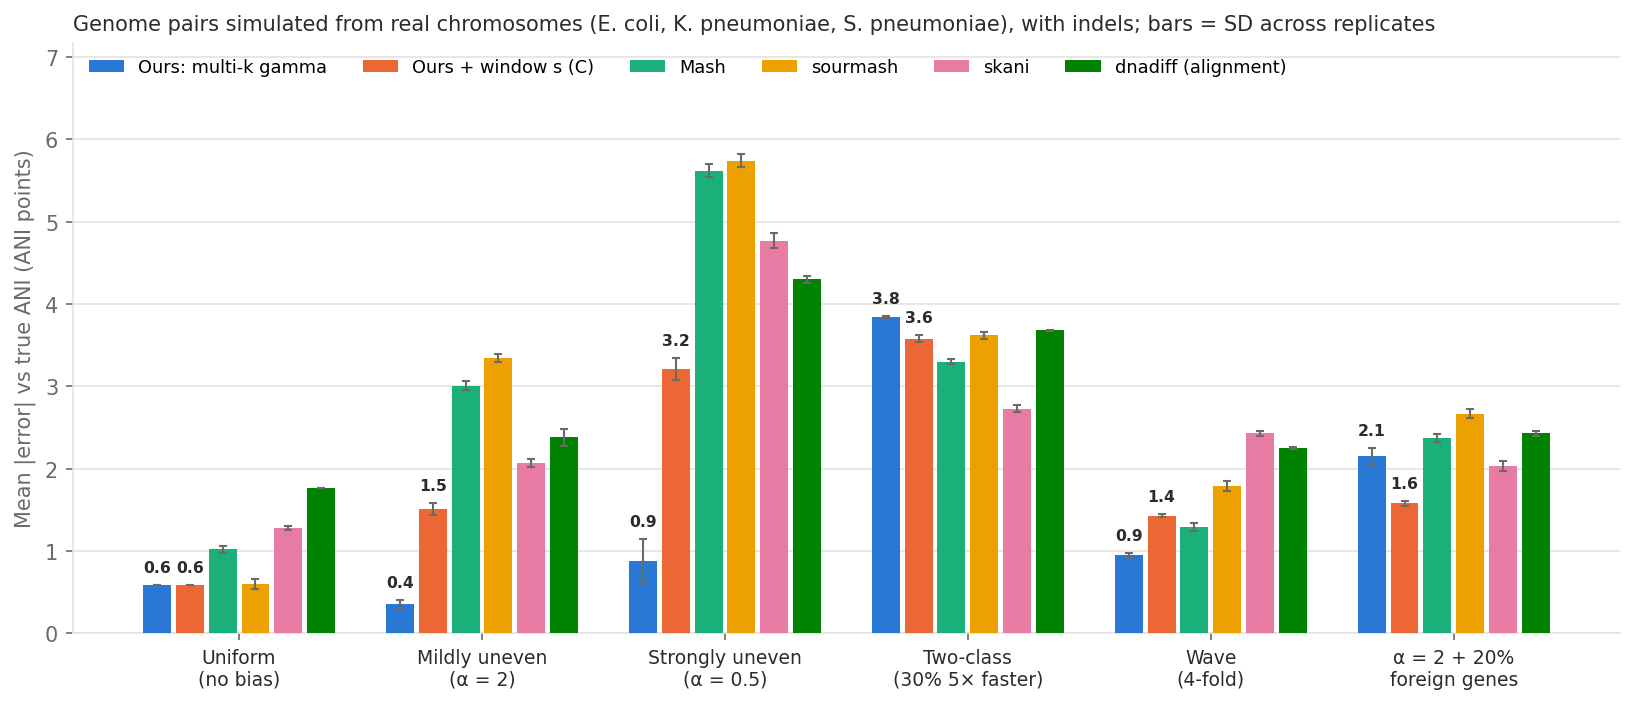

In [ ]:
# ---------------- analysis: everything is scored against the TRUE ANI ----------------
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 250)
files = [f for f in glob.glob(f"{OUT}/raw_w*.csv") if ("_quick" in f) == QUICK]
df = pd.concat([pd.read_csv(f) for f in files]).drop_duplicates("job").sort_values("job").reset_index(drop=True)
TOOLS_EST = ["Mash (tool)", "sourmash", "skani", "dnadiff"]
OURS = ["uniform (control)", "original", "C: window s", "G: window s + aligned-only"]
EST = TOOLS_EST + OURS
ORDER = ["Uniform", "Gamma a=2", "Gamma a=0.5", "Two-class", "Wave", "Gamma a=2 + 20% foreign genes"]
ORDER = [s for s in ORDER if s in set(df.setting)]
print(f"pairs finished: {len(df)}  |  replicates complete: {sorted(df.groupby('rep').size().loc[lambda x: x == x.max()].index.tolist())}")

# compare every estimator on the same pairs: those where skani and sourmash gave an estimate
# (skani gives none below ~82% ANI). dnadiff exists only for replicates 0-2, so its column uses that subset.
c = df.dropna(subset=["skani", "sourmash"]).copy()
for e in EST: c[f"err::{e}"] = (c[e] - c["true"]) * 100
print(f"pairs scored: {len(c)}" + (f" (dropped {len(df) - len(c)} where skani/sourmash gave no estimate; their true ANI is "
      f"{df.loc[~df.index.isin(c.index), 'true'].max():.3f} or lower)" if len(df) > len(c) else ""))

def per_setting(stat):
    t = {}
    for e in EST:
        g = c.dropna(subset=[e]).groupby("setting")[f"err::{e}"]
        t[e] = (g.mean() if stat == "mean" else g.apply(lambda x: x.abs().mean())).reindex(ORDER)
    t = pd.DataFrame(t)
    t.loc["ALL uneven"] = [c[c.setting != "Uniform"].dropna(subset=[e])[f"err::{e}"].pipe(lambda x: x.mean() if stat == "mean" else x.abs().mean()) for e in EST]
    return t.round(2)

print("\n=== Mean error vs TRUE ANI (ANI points; + = overestimates) ===")
mean_err = per_setting("mean"); print(mean_err.to_string())
print("\n=== Mean |error| vs TRUE ANI (ANI points) ===")
abs_err = per_setting("abs"); print(abs_err.to_string())

# variation between replicates (proposal: a difference counts only if it exceeds this)
rep_abs = c.groupby(["setting", "rep"]).apply(lambda d: pd.Series({e: d[f"err::{e}"].abs().mean() for e in EST}))
rep_sd = rep_abs.groupby("setting").std().reindex(ORDER).round(2)
print("\n=== SD of mean |error| across replicates (the noise level) ===")
print(rep_sd.to_string())

# 95% threshold: pairs within 0.5 points of the line are coin flips, so they are left out of this count
clear = c[(c.true - 0.95).abs() > 0.005]
def wrong(d, e):
    d = d.dropna(subset=[e]); return int((((d.true < .95) & (d[e] >= .95)) | ((d.true >= .95) & (d[e] < .95))).sum())
mis = pd.DataFrame({e: [wrong(clear[clear.setting == s], e) for s in ORDER] + [wrong(clear, e)] for e in EST}, index=ORDER + ["TOTAL"])
print(f"\n=== Wrong side of the 95% species line (excluding pairs within 0.5 pt of it; n = {len(clear)}, dnadiff on reps 0-2 only) ===")
print(mis.to_string())

# paired comparison: our original method vs each tool, uneven settings, bootstrap over pairs
print("\n=== Our original method minus each tool: difference in mean |error| (negative = ours better), uneven settings ===")
u = c[c.setting != "Uniform"]; rs = np.random.default_rng(0); rows = []
for e in TOOLS_EST + ["C: window s", "G: window s + aligned-only"]:
    d = u.dropna(subset=[e]); a = d["err::original"].abs().values; b = d[f"err::{e}"].abs().values
    idx = rs.integers(0, len(a), (5000, len(a))); boot = a[idx].mean(1) - b[idx].mean(1)
    rows.append({"vs": e, "n pairs": len(d), "difference": round(a.mean() - b.mean(), 2),
                 "95% CI": f"[{np.percentile(boot, 2.5):+.2f}, {np.percentile(boot, 97.5):+.2f}]"})
paired = pd.DataFrame(rows); print(paired.to_string(index=False))

print("\n=== Mean |error| by genome (uneven settings) ===")
print(pd.DataFrame({e: u.dropna(subset=[e]).groupby("genome")[f"err::{e}"].apply(lambda x: x.abs().mean()) for e in EST}).round(2).to_string())

print("\n=== Does the method recover the unevenness? fitted alpha (median) and shared fraction ===")
print(c.groupby("setting")[["alpha_orig", "alpha_C", "s_orig", "s_window", "true_s"]].median().reindex(ORDER).round(2).to_string())

for name, t in [("mean_error", mean_err), ("mean_abs_error", abs_err), ("replicate_sd", rep_sd), ("misclassified", mis)]:
    t.to_csv(f"{OUT}/summary_{name}{'_quick' if QUICK else ''}.csv")
paired.to_csv(f"{OUT}/summary_paired_bootstrap{'_quick' if QUICK else ''}.csv", index=False)

# ---------------- figure ----------------
SERIES = [("original", "Ours: multi-k gamma", "#2a78d6"), ("C: window s", "Ours + window s (C)", "#eb6834"),
          ("Mash (tool)", "Mash", "#1baf7a"), ("sourmash", "sourmash", "#eda100"), ("skani", "skani", "#e87ba4"),
          ("dnadiff", "dnadiff (alignment)", "#008300")]
LABELS = {"Uniform": "Uniform\n(no bias)", "Gamma a=2": "Mildly uneven\n(α = 2)", "Gamma a=0.5": "Strongly uneven\n(α = 0.5)",
          "Two-class": "Two-class\n(30% 5× faster)", "Wave": "Wave\n(4-fold)", "Gamma a=2 + 20% foreign genes": "α = 2 + 20%\nforeign genes"}
INK, INK2, GRID = "#2b2b29", "#6b6a64", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2})
fig, ax = plt.subplots(figsize=(11, 4.8), dpi=150)
w = 0.135; x = np.arange(len(ORDER))
for i, (col, lab, colr) in enumerate(SERIES):
    v = abs_err.loc[ORDER, col].values; sd = np.nan_to_num(rep_sd.loc[ORDER, col].values)
    pos = x + (i - 2.5) * w
    ax.bar(pos, v, w - 0.02, color=colr, label=lab, zorder=3)
    ax.errorbar(pos, v, yerr=sd, fmt="none", ecolor=INK2, elinewidth=1, capsize=2, zorder=4)
    if i < 2:                                                     # label our two methods only
        for xi, vi, si in zip(pos, v, sd): ax.text(xi, vi + si + 0.12, f"{vi:.1f}", ha="center", va="bottom", fontsize=7.5, color=INK, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([LABELS[s] for s in ORDER], fontsize=9, color=INK)
ax.set_ylabel("Mean |error| vs true ANI (ANI points)")
ax.grid(axis="y", color=GRID, zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Genome pairs simulated from real chromosomes (E. coli, K. pneumoniae, S. pneumoniae), with indels; "
             "bars = SD across replicates", loc="left", color=INK, fontsize=10)
ax.legend(frameon=False, ncol=6, loc="upper left", fontsize=8.5)
ax.set_ylim(0, max(7, abs_err.loc[ORDER, [s[0] for s in SERIES]].values.max() * 1.25))
plt.tight_layout(); fig_path = f"{OUT}/fig_realsim_errors{'_quick' if QUICK else ''}.png"
plt.savefig(fig_path, bbox_inches="tight", facecolor="white"); print("Saved:", fig_path); plt.show()